# Visualization of Platemaps

__Author: Runxi Shen__

__Date: 2025-04-29__

This is a notebook that helps draw up the distribution of alleles and their types on a 384-well platemap to help me better understand the experimental set-ups of different batches and how we need to adjust our analyses pipeline to accommodate the changes accordingly.

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import sys
%matplotlib inline
sys.path.append("../../..")
from utils import *

## Disable truncation globally
pl.Config.set_tbl_rows(20)  # Show all rows
pl.Config.set_tbl_cols(40)  # Show all columns

## define control types
TC = ["EGFP"]
NC = ["RHEB", "MAPK9", "PRKACB", "SLIRP"]
PC = ["ALK", "ALK_Arg1275Gln", "PTK2B"]
cNC = ["Renilla"]
cPC = ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
       "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# CTRLS = TC + NC + PC

## Metadata

In [49]:
meta_dat_df = pd.read_csv("../../inputs/corrected_metadata/2025_03_batch15-16/B15-16_Metadata_041125.csv")
meta_dat_df
# meta_dat_df[meta_dat_df["symbol"]=="TPM1"]

,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,...,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele
0,AP2S1,AP2S1,FV_reLR_01,G01,7.0,FVrry_P05_Q01,A01,1,A01,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,high,AP2S1,NaN,AP2S1
1,AP2S1,AP2S1_Arg15Cys,VUSmut_GDEh06,B04,26.0,FVrry_P05_Q01,B01,2,C01,B15A1A2P1_R1,...,43C>T,Arg15Cys,215314.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AP2S1,AP2S1_Arg15His,VUSmut_GDEh06,G05,39.0,FVrry_P05_Q01,C01,3,E01,B15A1A2P1_R1,...,44G>A,Arg15His,215316.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,APOA1,APOA1,DisWTGDEh03,C05,35.0,FVrry_P05_Q01,D01,4,G01,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,APOA1,APOA1_Arg34Leu,VUSmut_GDEh09,C12,91.0,FVrry_P05_Q01,E01,5,I01,B15A1A2P1_R1,...,101G>T,Arg34Leu,215445.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318,ALK,ALK_Arg1275Gln,527 Controls,NaN,NaN,FVrry_P05_Q04,E05,37,J10,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
319,MAPK9,MAPK9_,527 Controls,NaN,NaN,FVrry_P05_Q04,F07,54,L14,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320,RHEB,RHEB_,527 Controls,NaN,NaN,FVrry_P05_Q04,E08,61,J16,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
321,SLIRP,SLIRP_,527 Controls,NaN,NaN,FVrry_P05_Q04,D09,68,H18,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
meta_dat_df["gene_allele"] = meta_dat_df["gene_allele"].apply(lambda x: x[:-1] if type(x)==str and x.endswith("_") else x)
meta_dat_df["gene_symbol"] = meta_dat_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
# all(meta_dat_df["gene_symbol"]==meta_dat_df["symbol"])
meta_dat_df[meta_dat_df["gene_symbol"]!=meta_dat_df["symbol"]]

meta_dat_df.insert(0, "plate_map_name", "B15A1A2_P1")
meta_dat_df.insert(1, "well_position", meta_dat_df["imaging_well"])
# meta_dat_df.to_csv("../../inputs/platemaps/2025_03_17_Batch_15/platemap/B15A1A2_P1.txt", sep="\t", index=False)

meta_dat_df["plate_map_name"] = "B16A1A2_P1"
# meta_dat_df.to_csv("../../inputs/platemaps/2025_03_17_Batch_16/platemap/B16A1A2_P1.txt", sep="\t", index=False)

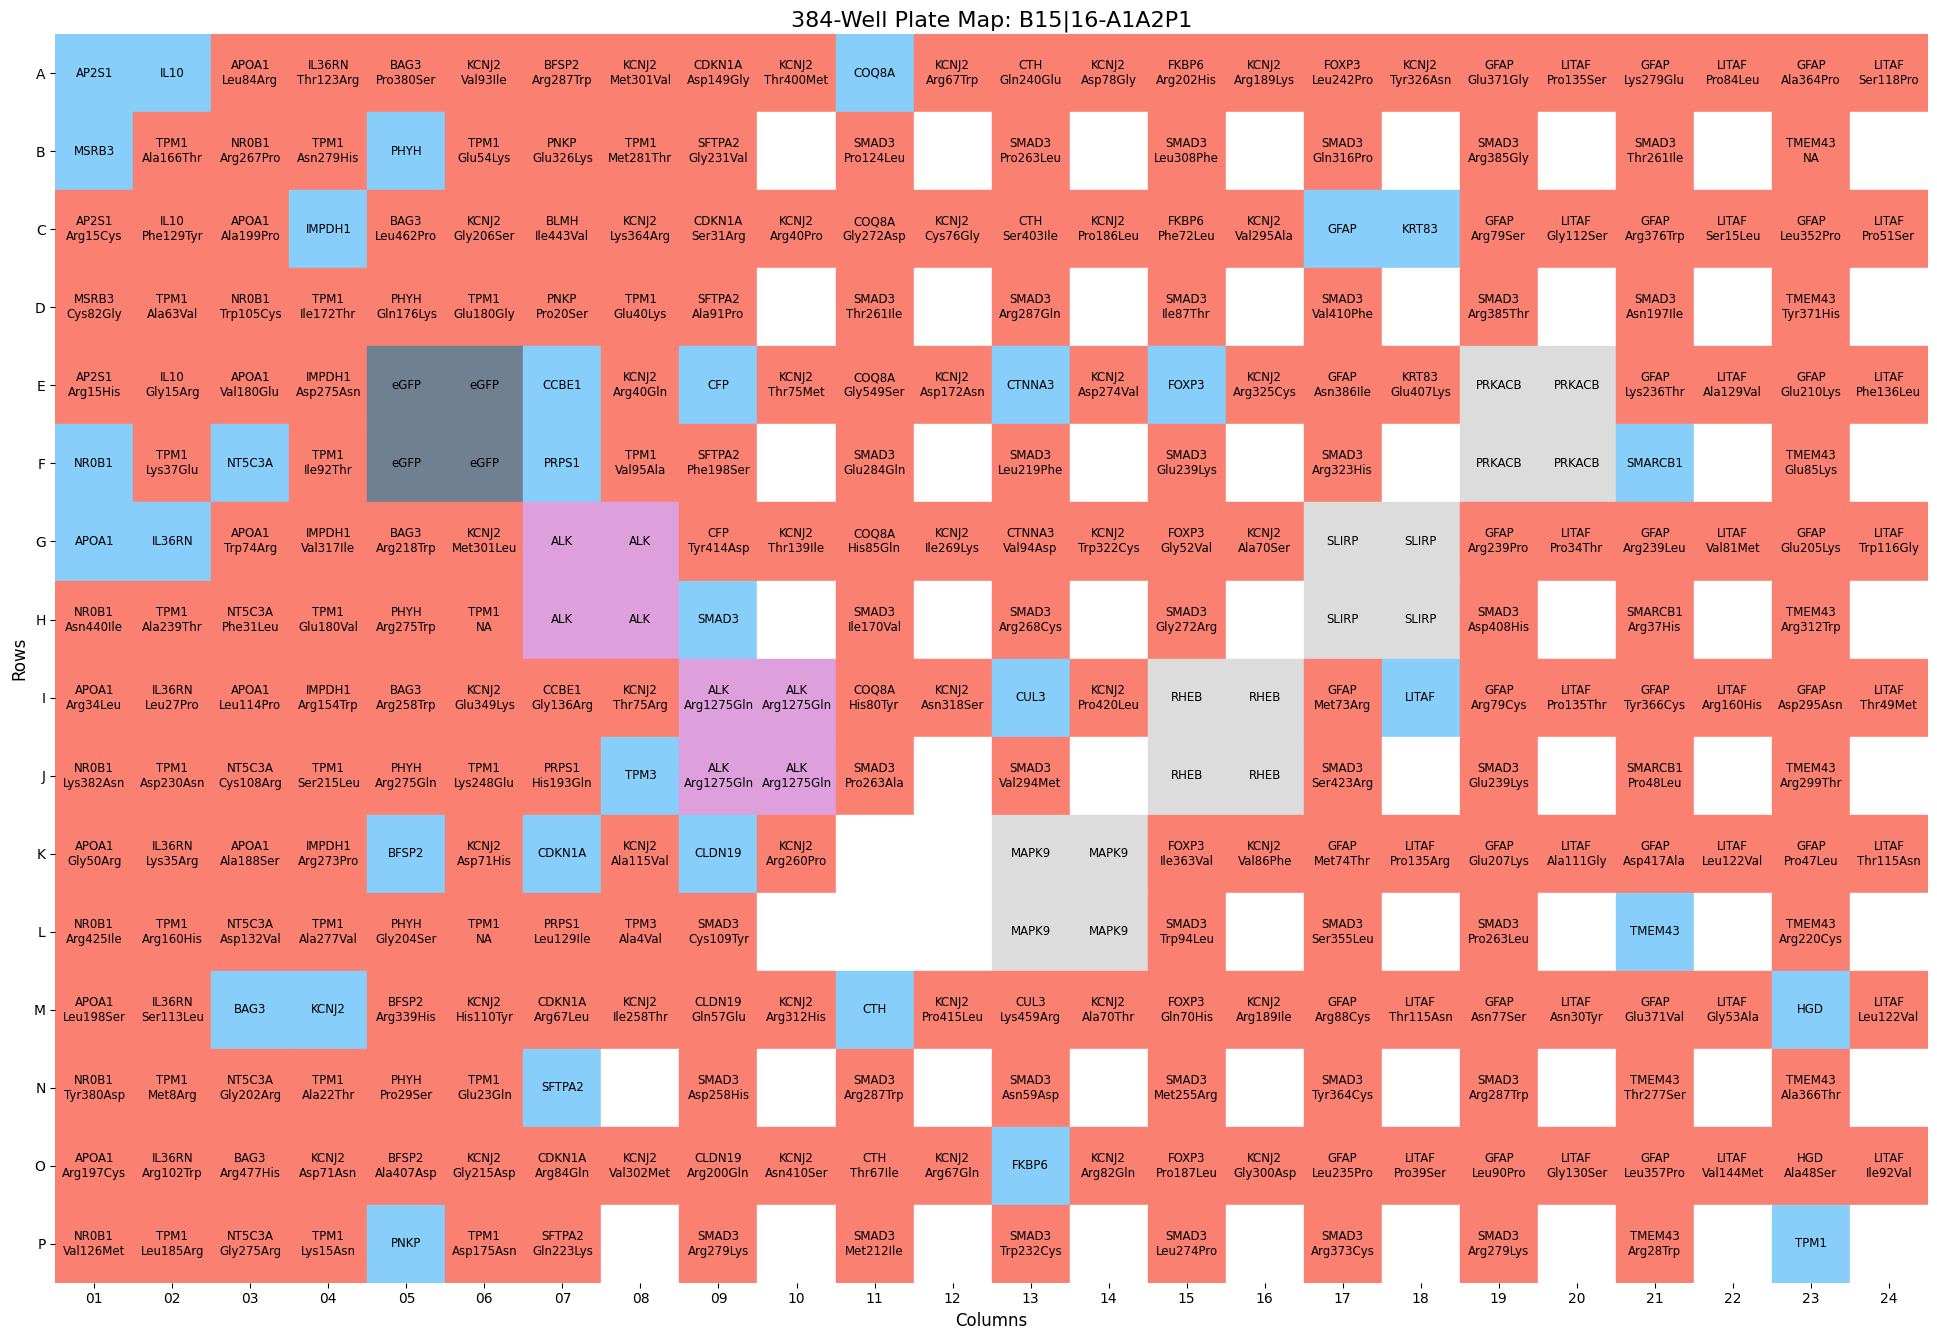

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele,gene_symbol,label
u32,str,str,str,str,str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,f64,f64,f64,str,str,str,str,str,str
0,"""01""","""""","""A""","""01""","""B16A1A2_P1""","""A01""","""AP2S1""","""AP2S1""","""FV_reLR_01""","""G01""",7.0,"""FVrry_P05_Q01""","""A01""",1,"""A01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",4983.0,null,null,null,null,null,null,"""high ""","""AP2S1""",null,"""AP2S1""","""AP2S1""","""AP2S1"""
1,"""01""","""""","""B""","""01""","""B16A1A2_P1""","""B01""","""MSRB3""","""MSRB3""","""FV_reLR_01""","""G03""",23.0,"""FVrry_P05_Q03""","""A01""",1,"""B01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",11435.0,null,null,null,null,null,null,"""verified""","""MSRB3""","""Cys82Gly""","""MSRB3_Cys82Gly""","""MSRB3""","""MSRB3"""
2,"""01""","""""","""C""","""01""","""B16A1A2_P1""","""C01""","""AP2S1""","""AP2S1_Arg15Cys""","""VUSmut_GDEh06""","""B04""",26.0,"""FVrry_P05_Q01""","""B01""",2,"""C01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4983.0,"""43C>T""","""Arg15Cys""",215314.0,null,null,null,null,null,null,null,"""AP2S1""","""AP2S1 Arg15Cys"""
3,"""01""","""""","""D""","""01""","""B16A1A2_P1""","""D01""","""MSRB3""","""MSRB3_Cys82Gly""","""VUSmut_GDEh05""","""F02""",14.0,"""FVrry_P05_Q03""","""B01""",2,"""D01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",11435.0,"""244T>G""","""Cys82Gly""",203467.0,null,null,null,null,null,null,null,"""MSRB3""","""MSRB3 Cys82Gly"""
4,"""01""","""""","""E""","""01""","""B16A1A2_P1""","""E01""","""AP2S1""","""AP2S1_Arg15His""","""VUSmut_GDEh06""","""G05""",39.0,"""FVrry_P05_Q01""","""C01""",3,"""E01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4983.0,"""44G>A""","""Arg15His""",215316.0,null,null,null,null,null,null,null,"""AP2S1""","""AP2S1 Arg15His"""
5,"""01""","""""","""F""","""01""","""B16A1A2_P1""","""F01""","""NR0B1""","""NR0B1""","""FV_reLR_01""","""G04""",31.0,"""FVrry_P05_Q03""","""C01""",3,"""F01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",7215.0,null,null,null,null,null,null,"""high ""","""NR0B1""",null,"""NR0B1""","""NR0B1""","""NR0B1"""
6,"""01""","""""","""G""","""01""","""B16A1A2_P1""","""G01""","""APOA1""","""APOA1""","""DisWTGDEh03""","""C05""",35.0,"""FVrry_P05_Q01""","""D01""",4,"""G01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",5613.0,null,null,null,null,null,null,null,null,null,null,"""APOA1""","""APOA1"""
7,"""01""","""""","""H""","""01""","""B16A1A2_P1""","""H01""","""NR0B1""","""NR0B1_Asn440Ile""","""VUSmut_GDEh09""","""B01""",2.0,"""FVrry_P05_Q03""","""D01""",4,"""H01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",7215.0,"""1319A>T""","""Asn440Ile""",216202.0,null,null,null,null,null,null,null,"""NR0B1""","""NR0B1 Asn440Ile"""
8,"""01""","""""","""I""","""01""","""B16A1A2_P1""","""I01""","""APOA1""","""APOA1_Arg34Leu""","""VUSmut_GDEh09""","""C12""",91.0,"""FVrry_P05_Q01""","""E01""",5,"""I01""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",5613.0,"""101G>T""","""Arg34Leu""",215445.0,null,null,null,null,null,null,null,"""APOA1""","""APOA1 Arg34Leu"""


In [33]:
meta_dat_df = pl.DataFrame(meta_dat_df)
plot_platemap(meta_dat_df, plate_name="B15|16-A1A2P1", well_pos_col="imaging_well")

## Metadata QC round 2

Aug 7, 2025

Need to remove KCNJ2 reference well

In [19]:
for batch in os.listdir("../../outputs/corrected_platemaps"):
    if batch.startswith("2025_03"):
        plate_map_file = os.listdir(f"../../outputs/corrected_platemaps/{batch}/platemap/")[0]
        meta_data_df = pl.read_csv(f"../../outputs/corrected_platemaps/{batch}/platemap/{plate_map_file}", separator="\t")
        display(meta_data_df.filter(
            pl.col("gene_allele").str.contains("KCNJ2")
        ))

        meta_data_df = meta_data_df.with_columns(
            pl.when(pl.col("gene_allele")=="KCNJ2")
            .then(pl.lit(None))
            .otherwise(pl.col("node_type"))
            .alias("node_type"),
            pl.when(pl.col("gene_allele")=="KCNJ2")
            .then(pl.lit(None))
            .otherwise(pl.col("symbol"))
            .alias("symbol"),
            pl.when(pl.col("gene_allele")=="KCNJ2")
            .then(pl.lit(None))
            .otherwise(pl.col("gene_allele"))
            .alias("gene_allele")
        )
        
        display(meta_data_df.filter(
            pl.col("gene_allele").str.contains("KCNJ2")
        ))
        display(meta_data_df.filter(
            pl.col("well_position").str.contains("A02")
        ))

        meta_data_df.write_csv(f"../../outputs/corrected_platemaps/{batch}/platemap/{plate_map_file}", separator="\t")

plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B15A1A2P1_R1""","""A02""","""KCNJ2""","""KCNJ2""","""FV_reLR_01""","""C02""",11.0,"""FVrry_P05_Q02""","""A01""",1,"""A02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",53065.0,null,null,null,null,null,null,"""verified"""
"""B15A1A2P1_R1""","""G02""","""KCNJ2""","""KCNJ2_Glu17Arg""","""FV_reLR_01""","""E03""",21.0,"""FVrry_P05_Q02""","""D01""",4,"""G02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",8151.0,null,null,null,null,null,null,"""verified """
"""B15A1A2P1_R1""","""O04""","""KCNJ2""","""KCNJ2_Asp71Asn""","""VUSmut_GDEh03""","""A07""",49.0,"""FVrry_P05_Q02""","""H02""",16,"""O04""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>A""","""Asp71Asn""",2608.0,null,null,null,null
"""B15A1A2P1_R1""","""A06""","""KCNJ2""","""KCNJ2_Val93Ile""","""VUSmut_GDEh03""","""A08""",57.0,"""FVrry_P05_Q02""","""A03""",17,"""A06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""277G>A""","""Val93Ile""",2618.0,null,null,null,null
"""B15A1A2P1_R1""","""C06""","""KCNJ2""","""KCNJ2_Gly206Ser""","""FV_reLR_01""","""E07""",53.0,"""FVrry_P05_Q02""","""B03""",18,"""C06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""616G>A""","""Gly206Ser""",2628.0,null,null,null,"""verified"""
"""B15A1A2P1_R1""","""G06""","""KCNJ2""","""KCNJ2_Met301Leu""","""VUSmut_GDEh03""","""A10""",73.0,"""FVrry_P05_Q02""","""D03""",20,"""G06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""901A>C""","""Met301Leu""",2643.0,null,null,null,null
"""B15A1A2P1_R1""","""I06""","""KCNJ2""","""KCNJ2_Glu349Lys""","""VUSmut_GDEh03""","""A11""",81.0,"""FVrry_P05_Q02""","""E03""",21,"""I06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""1045G>A""","""Glu349Lys""",2654.0,null,null,null,null
"""B15A1A2P1_R1""","""K06""","""KCNJ2""","""KCNJ2_Asp71His""","""VUSmut_GDEh03""","""B07""",50.0,"""FVrry_P05_Q02""","""F03""",22,"""K06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>C""","""Asp71His""",2609.0,null,null,null,null
"""B15A1A2P1_R1""","""M06""","""KCNJ2""","""KCNJ2_His110Tyr""","""VUSmut_GDEh03""","""B08""",58.0,"""FVrry_P05_Q02""","""G03""",23,"""M06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""328C>T""","""His110Tyr""",2619.0,null,null,null,null


plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B15A1A2P1_R1""","""G02""","""KCNJ2""","""KCNJ2_Glu17Arg""","""FV_reLR_01""","""E03""",21.0,"""FVrry_P05_Q02""","""D01""",4,"""G02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",8151.0,null,null,null,null,null,null,"""verified """
"""B15A1A2P1_R1""","""O04""","""KCNJ2""","""KCNJ2_Asp71Asn""","""VUSmut_GDEh03""","""A07""",49.0,"""FVrry_P05_Q02""","""H02""",16,"""O04""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>A""","""Asp71Asn""",2608.0,null,null,null,null
"""B15A1A2P1_R1""","""A06""","""KCNJ2""","""KCNJ2_Val93Ile""","""VUSmut_GDEh03""","""A08""",57.0,"""FVrry_P05_Q02""","""A03""",17,"""A06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""277G>A""","""Val93Ile""",2618.0,null,null,null,null
"""B15A1A2P1_R1""","""C06""","""KCNJ2""","""KCNJ2_Gly206Ser""","""FV_reLR_01""","""E07""",53.0,"""FVrry_P05_Q02""","""B03""",18,"""C06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""616G>A""","""Gly206Ser""",2628.0,null,null,null,"""verified"""
"""B15A1A2P1_R1""","""G06""","""KCNJ2""","""KCNJ2_Met301Leu""","""VUSmut_GDEh03""","""A10""",73.0,"""FVrry_P05_Q02""","""D03""",20,"""G06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""901A>C""","""Met301Leu""",2643.0,null,null,null,null
"""B15A1A2P1_R1""","""I06""","""KCNJ2""","""KCNJ2_Glu349Lys""","""VUSmut_GDEh03""","""A11""",81.0,"""FVrry_P05_Q02""","""E03""",21,"""I06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""1045G>A""","""Glu349Lys""",2654.0,null,null,null,null
"""B15A1A2P1_R1""","""K06""","""KCNJ2""","""KCNJ2_Asp71His""","""VUSmut_GDEh03""","""B07""",50.0,"""FVrry_P05_Q02""","""F03""",22,"""K06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>C""","""Asp71His""",2609.0,null,null,null,null
"""B15A1A2P1_R1""","""M06""","""KCNJ2""","""KCNJ2_His110Tyr""","""VUSmut_GDEh03""","""B08""",58.0,"""FVrry_P05_Q02""","""G03""",23,"""M06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""328C>T""","""His110Tyr""",2619.0,null,null,null,null
"""B15A1A2P1_R1""","""O06""","""KCNJ2""","""KCNJ2_Gly215Asp""","""VUSmut_GDEh03""","""B09""",66.0,"""FVrry_P05_Q02""","""H03""",24,"""O06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""644G>A""","""Gly215Asp""",2629.0,null,null,null,null


plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B15A1A2P1_R1""","""A02""",null,null,"""FV_reLR_01""","""C02""",11.0,"""FVrry_P05_Q02""","""A01""",1,"""A02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""",null,53065.0,null,null,null,null,null,null,"""verified"""


plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B16A1A2P1_R1""","""A02""","""KCNJ2""","""KCNJ2""","""FV_reLR_01""","""C02""",11.0,"""FVrry_P05_Q02""","""A01""",1,"""A02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""disease_wt""",53065.0,null,null,null,null,null,null,"""verified"""
"""B16A1A2P1_R1""","""G02""","""KCNJ2""","""KCNJ2_Glu17Arg""","""FV_reLR_01""","""E03""",21.0,"""FVrry_P05_Q02""","""D01""",4,"""G02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",8151.0,null,null,null,null,null,null,"""verified """
"""B16A1A2P1_R1""","""O04""","""KCNJ2""","""KCNJ2_Asp71Asn""","""VUSmut_GDEh03""","""A07""",49.0,"""FVrry_P05_Q02""","""H02""",16,"""O04""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>A""","""Asp71Asn""",2608.0,null,null,null,null
"""B16A1A2P1_R1""","""A06""","""KCNJ2""","""KCNJ2_Val93Ile""","""VUSmut_GDEh03""","""A08""",57.0,"""FVrry_P05_Q02""","""A03""",17,"""A06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""277G>A""","""Val93Ile""",2618.0,null,null,null,null
"""B16A1A2P1_R1""","""C06""","""KCNJ2""","""KCNJ2_Gly206Ser""","""FV_reLR_01""","""E07""",53.0,"""FVrry_P05_Q02""","""B03""",18,"""C06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""616G>A""","""Gly206Ser""",2628.0,null,null,null,"""verified"""
"""B16A1A2P1_R1""","""G06""","""KCNJ2""","""KCNJ2_Met301Leu""","""VUSmut_GDEh03""","""A10""",73.0,"""FVrry_P05_Q02""","""D03""",20,"""G06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""901A>C""","""Met301Leu""",2643.0,null,null,null,null
"""B16A1A2P1_R1""","""I06""","""KCNJ2""","""KCNJ2_Glu349Lys""","""VUSmut_GDEh03""","""A11""",81.0,"""FVrry_P05_Q02""","""E03""",21,"""I06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""1045G>A""","""Glu349Lys""",2654.0,null,null,null,null
"""B16A1A2P1_R1""","""K06""","""KCNJ2""","""KCNJ2_Asp71His""","""VUSmut_GDEh03""","""B07""",50.0,"""FVrry_P05_Q02""","""F03""",22,"""K06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>C""","""Asp71His""",2609.0,null,null,null,null
"""B16A1A2P1_R1""","""M06""","""KCNJ2""","""KCNJ2_His110Tyr""","""VUSmut_GDEh03""","""B08""",58.0,"""FVrry_P05_Q02""","""G03""",23,"""M06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""328C>T""","""His110Tyr""",2619.0,null,null,null,null


plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B16A1A2P1_R1""","""G02""","""KCNJ2""","""KCNJ2_Glu17Arg""","""FV_reLR_01""","""E03""",21.0,"""FVrry_P05_Q02""","""D01""",4,"""G02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",8151.0,null,null,null,null,null,null,"""verified """
"""B16A1A2P1_R1""","""O04""","""KCNJ2""","""KCNJ2_Asp71Asn""","""VUSmut_GDEh03""","""A07""",49.0,"""FVrry_P05_Q02""","""H02""",16,"""O04""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>A""","""Asp71Asn""",2608.0,null,null,null,null
"""B16A1A2P1_R1""","""A06""","""KCNJ2""","""KCNJ2_Val93Ile""","""VUSmut_GDEh03""","""A08""",57.0,"""FVrry_P05_Q02""","""A03""",17,"""A06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""277G>A""","""Val93Ile""",2618.0,null,null,null,null
"""B16A1A2P1_R1""","""C06""","""KCNJ2""","""KCNJ2_Gly206Ser""","""FV_reLR_01""","""E07""",53.0,"""FVrry_P05_Q02""","""B03""",18,"""C06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""616G>A""","""Gly206Ser""",2628.0,null,null,null,"""verified"""
"""B16A1A2P1_R1""","""G06""","""KCNJ2""","""KCNJ2_Met301Leu""","""VUSmut_GDEh03""","""A10""",73.0,"""FVrry_P05_Q02""","""D03""",20,"""G06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""901A>C""","""Met301Leu""",2643.0,null,null,null,null
"""B16A1A2P1_R1""","""I06""","""KCNJ2""","""KCNJ2_Glu349Lys""","""VUSmut_GDEh03""","""A11""",81.0,"""FVrry_P05_Q02""","""E03""",21,"""I06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""1045G>A""","""Glu349Lys""",2654.0,null,null,null,null
"""B16A1A2P1_R1""","""K06""","""KCNJ2""","""KCNJ2_Asp71His""","""VUSmut_GDEh03""","""B07""",50.0,"""FVrry_P05_Q02""","""F03""",22,"""K06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""211G>C""","""Asp71His""",2609.0,null,null,null,null
"""B16A1A2P1_R1""","""M06""","""KCNJ2""","""KCNJ2_His110Tyr""","""VUSmut_GDEh03""","""B08""",58.0,"""FVrry_P05_Q02""","""G03""",23,"""M06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""328C>T""","""His110Tyr""",2619.0,null,null,null,null
"""B16A1A2P1_R1""","""O06""","""KCNJ2""","""KCNJ2_Gly215Asp""","""VUSmut_GDEh03""","""B09""",66.0,"""FVrry_P05_Q02""","""H03""",24,"""O06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",1.00016069e8,"""644G>A""","""Gly215Asp""",2629.0,null,null,null,null


plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,str,str,str,str
"""B16A1A2P1_R1""","""A02""",null,null,"""FV_reLR_01""","""C02""",11.0,"""FVrry_P05_Q02""","""A01""",1,"""A02""","""B15A1A2P1_R1""","""B16A1A2P1_R2""",null,53065.0,null,null,null,null,null,null,"""verified"""


## Metadata QC Round 1

In [3]:
meta_dat_df = pd.read_csv("../../inputs/corrected_metadata/2025_03_batch15-16/B15B16_Metadata_seq_update_050625.csv")
mask = meta_dat_df['final_gene_allele'].notna() & (meta_dat_df['final_gene_allele'] != meta_dat_df['gene_allele'])
# meta_dat_df.loc[mask,:]
meta_dat_df.loc[mask, 'gene_allele'] = meta_dat_df.loc[mask, 'final_gene_allele']
meta_dat_df.loc[mask,:]

# meta_dat_df[meta_dat_df["symbol"]=="TPM1"]

,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,...,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele
96,IL10,KCNJ2,FV_reLR_01,C02,11.0,FVrry_P05_Q02,A01,1,A02,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,verified,KCNJ2,NaN,KCNJ2
99,IL36RN,KCNJ2_Glu17Arg,FV_reLR_01,E03,21.0,FVrry_P05_Q02,D01,4,G02,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,verified,KCNJ2,Glu17Arg,KCNJ2_Glu17Arg
192,MSRB3,MSRB3_Cys82Gly,FV_reLR_01,G03,23.0,FVrry_P05_Q03,A01,1,B01,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,verified,MSRB3,Cys82Gly,MSRB3_Cys82Gly
214,PHYH,NR0B1_Trp105Cys,FV_reLR_02,A11,81.0,FVrry_P05_Q03,G03,23,N05,B15A1A2P1_R1,...,85C>T,Pro29Ser,3351.0,NaN,NaN,NaN,high,NR0B1,Trp105Cys,NR0B1_Trp105Cys
218,PRPS1,TPM1_Asp175Asn,FV_reLR_01,E05,37.0,FVrry_P05_Q03,C04,27,F07,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,verified,TPM1,Asp175Asn,TPM1_Asp175Asn
274,SMARCB1,TPM1_Arg238Trp,FV_reLR_01,D03,20.0,FVrry_P05_Q03,C11,83,F21,B15A1A2P1_R1,...,NaN,NaN,NaN,NaN,NaN,NaN,verified,TPM1,Arg238Trp,TPM1_Arg238Trp
301,TPM1,TPM1,FV_reLR_01,G10,79.0,FVrry_P05_Q04,F02,14,L04,B15A1A2P1_R1,...,830C>T,Ala277Val,201749.0,NaN,NaN,NaN,verified,TPM1,NaN,TPM1
311,TPM1,TPM1,FV_reLR_02,B01,2.0,FVrry_P05_Q04,H03,24,P06,B15A1A2P1_R1,...,523G>A,Asp175Asn,8952.0,NaN,NaN,NaN,verified,TPM1,NaN,TPM1


In [4]:
meta_dat_df["gene_allele"] = meta_dat_df["gene_allele"].apply(lambda x: x[:-1] if type(x)==str and x.endswith("_") else x)
meta_dat_df["gene_symbol"] = meta_dat_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
meta_dat_df["symbol"] = meta_dat_df["gene_symbol"]

## mask_null_node
# meta_dat_df["node_type"].unique()
mask_null_node = meta_dat_df["gene_allele"].isna() | meta_dat_df["gene_allele"].str.contains("null") | meta_dat_df["gene_allele"].str.contains("_NA")
meta_dat_df.loc[mask_null_node,]

meta_dat_df.loc[mask_null_node, "symbol"] = np.nan
meta_dat_df.loc[mask_null_node, "gene_allele"] = np.nan
meta_dat_df.loc[mask_null_node, "node_type"] = np.nan

mask_allele = meta_dat_df['gene_allele'].notna() & meta_dat_df["gene_allele"].str.contains("_")
meta_dat_df.loc[mask_allele, "node_type"] = "allele"

mask_wt = (meta_dat_df['gene_allele']==meta_dat_df['symbol']) & (meta_dat_df['node_type']=="allele")
meta_dat_df.loc[mask_wt, "node_type"] = "disease_wt"

# assert(all(meta_dat_df["gene_symbol"]==meta_dat_df["symbol"]))
meta_dat_df[meta_dat_df["gene_symbol"]!=meta_dat_df["symbol"]]
meta_dat_df.drop(columns=["gene","allele","final_gene_allele","gene_symbol"], inplace=True)

meta_dat_df.insert(0, "plate_map_name", "B15A1A2P1_R1")
meta_dat_df.insert(1, "well_position", meta_dat_df["imaging_well"])
os.makedirs("../../outputs/corrected_platemaps/2025_03_17_Batch_15/platemap")
meta_dat_df.to_csv("../../outputs/corrected_platemaps/2025_03_17_Batch_15/platemap/B15A1A2P1_R1.txt", sep="\t", index=False)

meta_dat_df["plate_map_name"] = "B16A1A2P1_R1"
os.makedirs("../../outputs/corrected_platemaps/2025_03_17_Batch_16/platemap")
meta_dat_df.to_csv("../../outputs/corrected_platemaps/2025_03_17_Batch_16/platemap/B16A1A2P1_R1.txt", sep="\t", index=False)

In [5]:
meta_dat_df["node_type"].unique()

array(['disease_wt', 'allele', 'TC', 'PC', nan, 'NC'], dtype=object)

In [6]:
# meta_dat_df[meta_dat_df["symbol"]=="TPM1"]

In [7]:
result_count = meta_dat_df.groupby(['node_type', 'gene_allele']).size().reset_index(name='count')
result_count[result_count["node_type"]=="allele"]

,node_type,gene_allele,count
6,allele,ALK_Arg1275Gln,4
7,allele,AP2S1_Arg15Cys,1
8,allele,AP2S1_Arg15His,1
9,allele,APOA1_Ala188Ser,1
10,allele,APOA1_Ala199Pro,1
...,...,...,...
250,allele,TPM1_Met281Thr,1
251,allele,TPM1_Met8Arg,1
252,allele,TPM1_Ser215Leu,1
253,allele,TPM1_Val95Ala,1


In [45]:
meta_dat_df.filter(pl.col("gene_allele").is_in(["TPM1_NA"]))

plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,f64,f64,f64,str
"""B16A1A2P1_R1""","""H06""","""TPM1""","""TPM1_NA""","""VUSmut_GDEh08""","""H10""",80.0,"""FVrry_P05_Q04""","""D03""",20,"""H06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4723.0,null,null,null,null,null,null,null
"""B16A1A2P1_R1""","""L06""","""TPM1""","""TPM1_NA""","""VUSmut_GDEh09""","""D04""",28.0,"""FVrry_P05_Q04""","""F03""",22,"""L06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4723.0,null,null,null,null,null,null,null
